# Hands-On Data Lab Implementation
**Assignment:** 2 — Hands-On Data Lab Implementation  
**Track:** Data Science Internship  
**Topic:** Build a working data analysis environment and complete practical exercises  
**Author:** Data Science Intern  

---

### Project Objectives
1. **Set Up the Data Science Environment** — Install and configure Python, Jupyter Notebook, and essential libraries including NumPy, Pandas, Matplotlib, Seaborn, and Scikit-learn.
2. **Work with Data Using Pandas & NumPy** — Load datasets and practice data selection, filtering, sorting, grouping, aggregation, merging, transformation, and numerical operations.
3. **Perform Data Cleaning** — Identify and handle missing values, duplicate records, inconsistent data, incorrect data types, and basic data-quality issues.
4. **Create Data Visualizations** — Build meaningful bar charts, line charts, histograms, scatter plots, box plots, and other suitable visualizations using Matplotlib and Seaborn.
5. **Perform Basic Data Analysis** — Calculate descriptive statistics and analyze distributions, relationships, correlations, and patterns within datasets to generate initial observations.
6. **Complete & Document Practical Exercises** — Create a structured Jupyter Notebook containing code, outputs, visualizations, observations, and insights from all exercises, following clean and reproducible analysis practices.

---
## Section 1 — Data Science Environment Setup
### 1.1 Library Imports & Version Verification

In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 1: Environment Setup — Import all required libraries
# ─────────────────────────────────────────────────────────────────────────────
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# ── Reproducibility seed ──────────────────────────────────────────────────────
np.random.seed(42)
warnings.filterwarnings('ignore')

# ── Plot style ────────────────────────────────────────────────────────────────
STYLE = 'seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'seaborn-whitegrid'
plt.style.use(STYLE)
sns.set_palette('deep')

# ── Figures output directory ──────────────────────────────────────────────────
FIG_DIR = os.path.join('..', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# ── Print installed versions ──────────────────────────────────────────────────
import platform, sys
print('=' * 55)
print('  DATA SCIENCE ENVIRONMENT — VERSION REPORT')
print('=' * 55)
print(f'  Python        : {sys.version.split()[0]}')
print(f'  OS            : {platform.system()} {platform.release()}')
print(f'  NumPy         : {np.__version__}')
print(f'  Pandas        : {pd.__version__}')
print(f'  Matplotlib    : {plt.matplotlib.__version__}')
print(f'  Seaborn       : {sns.__version__}')
print(f'  Scikit-learn  : {sklearn.__version__}')
print('=' * 55)
print('  All libraries loaded successfully.')
print('=' * 55)

  DATA SCIENCE ENVIRONMENT — VERSION REPORT
  Python        : 3.12.10
  OS            : Windows 11
  NumPy         : 2.5.1
  Pandas        : 3.0.5
  Matplotlib    : 3.11.1
  Seaborn       : 0.13.2
  Scikit-learn  : 1.9.1
  All libraries loaded successfully.


### 1.2 Observation
> All five core data science libraries — NumPy, Pandas, Matplotlib, Seaborn, and Scikit-learn — are successfully installed and imported. The environment is configured with a fixed random seed (`42`) for reproducibility, and a dedicated `figures/` directory is ready for saving all plots.

---
## Section 2 — Working with Data Using Pandas & NumPy
### 2.1 Dataset Generation
We generate a realistic **retail sales dataset** with 500 transaction records covering multiple data types to practice all Pandas and NumPy operations.

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 2.1: Synthetic Retail Sales Dataset (500 records)
# ─────────────────────────────────────────────────────────────────────────────
n = 500

categories    = ['Electronics', 'Clothing', 'Groceries', 'Furniture', 'Sports']
regions       = ['North', 'South', 'East', 'West', 'Central']
payment_modes = ['Credit Card', 'Debit Card', 'Cash', 'UPI', 'Net Banking']
genders       = ['Male', 'Female']

# --- Core fields ---
order_ids    = [f'ORD-{10000 + i}' for i in range(n)]
dates        = pd.date_range(start='2023-01-01', periods=n, freq='D')
cat          = np.random.choice(categories, n, p=[0.30, 0.20, 0.25, 0.10, 0.15])
region       = np.random.choice(regions, n)
payment      = np.random.choice(payment_modes, n)
gender       = np.random.choice(genders, n)
age          = np.random.randint(18, 70, n)
units_sold   = np.random.randint(1, 20, n)
unit_price   = np.round(np.random.uniform(50, 5000, n), 2)
discount_pct = np.round(np.random.choice([0, 5, 10, 15, 20, 25], n,
                                          p=[0.30, 0.20, 0.20, 0.15, 0.10, 0.05]), 1)
revenue      = np.round(units_sold * unit_price * (1 - discount_pct / 100), 2)
rating       = np.round(np.clip(np.random.normal(3.8, 0.7, n), 1, 5), 1)
returned     = np.where(rating < 2.5, 1, np.random.binomial(1, 0.05, n))

df_raw = pd.DataFrame({
    'OrderID'    : order_ids,
    'Date'       : dates,
    'Category'   : cat,
    'Region'     : region,
    'Gender'     : gender,
    'Age'        : age,
    'PaymentMode': payment,
    'UnitsSold'  : units_sold,
    'UnitPrice'  : unit_price,
    'DiscountPct': discount_pct,
    'Revenue'    : revenue,
    'Rating'     : rating,
    'Returned'   : returned
})

# ── Inject realistic data quality issues for cleaning exercise ────────────────
np.random.seed(7)
miss_idx = np.random.choice(df_raw.index, size=30, replace=False)
df_raw.loc[miss_idx[:15], 'Rating']    = np.nan
df_raw.loc[miss_idx[15:], 'UnitPrice'] = np.nan

dup_idx = np.random.choice(df_raw.index, size=10, replace=False)
df_raw  = pd.concat([df_raw, df_raw.iloc[dup_idx]], ignore_index=True)

# Inconsistent casing in Gender
err_idx = np.random.choice(df_raw.index, size=15, replace=False)
df_raw.loc[err_idx, 'Gender'] = df_raw.loc[err_idx, 'Gender'].str.lower()

# Negative revenue entry (data error)
df_raw.loc[df_raw.index[3], 'Revenue'] = -999.0

# Save raw dataset
df_raw.to_csv(os.path.join('..', 'data', 'retail_sales_raw.csv'), index=False)
print(f'Raw dataset shape : {df_raw.shape}')
df_raw.head(8)

Raw dataset shape : (510, 13)


,OrderID,Date,Category,Region,Gender,Age,PaymentMode,UnitsSold,UnitPrice,DiscountPct,Revenue,Rating,Returned
0,ORD-10000,2023-01-01,Clothing,North,Female,53,Cash,19,1020.68,25,14544.69,3.6,0
1,ORD-10001,2023-01-02,Sports,North,Male,37,Debit Card,14,3073.36,15,36572.98,4.5,0
2,ORD-10002,2023-01-03,Groceries,North,Female,21,Debit Card,17,1439.38,25,18352.10,4.1,0
3,ORD-10003,2023-01-04,Groceries,Central,Female,24,Cash,3,1074.61,10,-999.00,3.8,0
4,ORD-10004,2023-01-05,Electronics,West,Male,18,UPI,7,2607.03,0,18249.21,3.9,0
5,ORD-10005,2023-01-06,Electronics,Central,Female,61,UPI,17,77.25,5,1247.59,3.4,0
6,ORD-10006,2023-01-07,Electronics,West,Male,62,Net Banking,12,87.94,10,949.75,3.7,1
7,ORD-10007,2023-01-08,Sports,Central,Female,59,Net Banking,9,1134.39,0,10209.51,3.3,1


### 2.2 Data Selection & Filtering

In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 2.2: Selection, Filtering, and Slicing
# ─────────────────────────────────────────────────────────────────────────────

# Label-based selection (loc)
print('── Label-based selection (first 3 rows, specific columns) ──')
print(df_raw.loc[0:2, ['OrderID', 'Category', 'Revenue', 'Rating']])

print('\n── Integer-position selection (iloc) ──')
print(df_raw.iloc[5:8, [0, 2, 10, 11]])

print('\n── Filter: Electronics with Revenue > 10,000 ──')
high_elec = df_raw[(df_raw['Category'] == 'Electronics') & (df_raw['Revenue'] > 10_000)]
print(f'   Records found: {len(high_elec)}')
print(high_elec[['OrderID', 'Revenue', 'Rating', 'Region']].head())

print('\n── Filter: Orders from North or South with UPI payment ──')
ns_upi = df_raw[df_raw['Region'].isin(['North', 'South']) & (df_raw['PaymentMode'] == 'UPI')]
print(f'   Records found: {len(ns_upi)}')

── Label-based selection (first 3 rows, specific columns) ──
     OrderID   Category   Revenue  Rating
0  ORD-10000   Clothing  14544.69     3.6
1  ORD-10001     Sports  36572.98     4.5
2  ORD-10002  Groceries  18352.10     4.1

── Integer-position selection (iloc) ──
     OrderID     Category   Revenue  Rating
5  ORD-10005  Electronics   1247.59     3.4
6  ORD-10006  Electronics    949.75     3.7
7  ORD-10007       Sports  10209.51     3.3

── Filter: Electronics with Revenue > 10,000 ──
   Records found: 105
      OrderID   Revenue  Rating   Region
4   ORD-10004  18249.21     3.9     West
10  ORD-10010  22455.68     3.0  Central
13  ORD-10013  16561.34     NaN  Central
14  ORD-10014  15779.08     3.7    North
15  ORD-10015  29371.73     3.4    South

── Filter: Orders from North or South with UPI payment ──
   Records found: 33


### 2.3 Sorting & Ranking

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 2.3: Sorting and Ranking
# ─────────────────────────────────────────────────────────────────────────────

print('── Top 5 Orders by Revenue ──')
top5_rev = df_raw.nlargest(5, 'Revenue')[['OrderID', 'Category', 'Region', 'Revenue']]
print(top5_rev.to_string(index=False))

print('\n── Sorted by Category (asc) then Revenue (desc) ──')
sorted_df = df_raw.sort_values(['Category', 'Revenue'], ascending=[True, False])
print(sorted_df[['Category', 'OrderID', 'Revenue']].head(8).to_string(index=False))

df_raw['RevenueRank'] = df_raw.groupby('Region')['Revenue'].rank(ascending=False, method='dense')
print('\n── Revenue Rank within Region (sample) ──')
print(df_raw[['Region', 'OrderID', 'Revenue', 'RevenueRank']].sort_values(
    ['Region', 'RevenueRank']).head(10).to_string(index=False))

── Top 5 Orders by Revenue ──
  OrderID  Category  Region  Revenue
ORD-10143  Clothing Central 93496.53
ORD-10025 Furniture    East 84891.92
ORD-10238 Groceries   North 81898.23
ORD-10349 Groceries   South 81333.07
ORD-10119 Groceries    East 79793.60

── Sorted by Category (asc) then Revenue (desc) ──
Category   OrderID  Revenue
Clothing ORD-10143 93496.53
Clothing ORD-10246 79401.38
Clothing ORD-10253 63559.65
Clothing ORD-10282 61225.88
Clothing ORD-10138 60967.95
Clothing ORD-10494 60436.11
Clothing ORD-10024 52892.70
Clothing ORD-10024 52892.70

── Revenue Rank within Region (sample) ──
 Region   OrderID  Revenue  RevenueRank
Central ORD-10143 93496.53          1.0
Central ORD-10032 68104.74          2.0
Central ORD-10211 67168.76          3.0
Central ORD-10253 63559.65          4.0
Central ORD-10247 60003.06          5.0
Central ORD-10184 55456.53          6.0
Central ORD-10207 55243.07          7.0
Central ORD-10136 46856.26          8.0
Central ORD-10378 45858.68          9.0
C

### 2.4 Grouping, Aggregation & Merging

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 2.4: Grouping, Aggregation and Merging
# ─────────────────────────────────────────────────────────────────────────────

cat_summary = df_raw.groupby('Category').agg(
    TotalRevenue = ('Revenue', 'sum'),
    AvgRevenue   = ('Revenue', 'mean'),
    TotalOrders  = ('OrderID', 'count'),
    AvgRating    = ('Rating', 'mean'),
    ReturnRate   = ('Returned', 'mean')
).round(2).reset_index()
print('── Category-Level Aggregation Summary ──')
print(cat_summary.to_string(index=False))

print('\n── Revenue Pivot Table (Region x Category) ──')
pivot = df_raw.pivot_table(values='Revenue', index='Region', columns='Category',
                            aggfunc='sum', fill_value=0).round(0)
print(pivot)

tier_lookup = pd.DataFrame({
    'Region'     : ['North', 'South', 'East', 'West', 'Central'],
    'LoyaltyTier': ['Gold', 'Silver', 'Platinum', 'Bronze', 'Silver']
})
df_merged = df_raw.merge(tier_lookup, on='Region', how='left')
print('\n── After Merging Loyalty Tier (sample) ──')
print(df_merged[['OrderID', 'Region', 'LoyaltyTier', 'Revenue']].head(5).to_string(index=False))

── Category-Level Aggregation Summary ──
   Category  TotalRevenue  AvgRevenue  TotalOrders  AvgRating  ReturnRate
   Clothing    2040812.73    22426.51           91       3.81        0.05
Electronics    3354468.24    21503.00          156       3.79        0.06
  Furniture    1293803.51    25876.07           50       3.87        0.10
  Groceries    2342124.68    18156.01          129       3.83        0.06
     Sports    2061148.49    24537.48           84       3.78        0.06

── Revenue Pivot Table (Region x Category) ──
Category  Clothing  Electronics  Furniture  Groceries    Sports
Region                                                         
Central   397665.0     739728.0   108555.0   459843.0  274959.0
East      369087.0     546376.0   536386.0   438463.0  429290.0
North     334956.0    1013464.0   194557.0   659475.0  532283.0
South     547172.0     503938.0   290722.0   442027.0  484326.0
West      391932.0     550963.0   163584.0   342316.0  340291.0

── After Merging Lo

### 2.5 NumPy Numerical Operations

In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 2.5: NumPy Numerical Operations
# ─────────────────────────────────────────────────────────────────────────────

rev_array = df_raw['Revenue'].dropna().values

print('── NumPy Numerical Operations on Revenue Array ──')
print(f'  Array shape         : {rev_array.shape}')
print(f'  Sum                 : {np.sum(rev_array):>15,.2f}')
print(f'  Mean                : {np.mean(rev_array):>15,.2f}')
print(f'  Median              : {np.median(rev_array):>15,.2f}')
print(f'  Std Dev             : {np.std(rev_array, ddof=1):>15,.2f}')
print(f'  Min                 : {np.min(rev_array):>15,.2f}')
print(f'  Max                 : {np.max(rev_array):>15,.2f}')
print(f'  25th Percentile     : {np.percentile(rev_array, 25):>15,.2f}')
print(f'  75th Percentile     : {np.percentile(rev_array, 75):>15,.2f}')

print('\n── Vector Operations ──')
rev_with_tax = np.round(rev_array * 1.18, 2)
print(f'  Revenue + 18% GST (first 5): {rev_with_tax[:5]}')

log_rev = np.log1p(np.clip(rev_array, 0, None))
print(f'  Log-transformed revenue (first 5): {np.round(log_rev[:5], 4)}')

z_scores = (rev_array - np.mean(rev_array)) / np.std(rev_array, ddof=1)
outlier_mask = np.abs(z_scores) > 3
print(f'\n  Outliers with |z| > 3: {outlier_mask.sum()} detected')

── NumPy Numerical Operations on Revenue Array ──
  Array shape         : (510,)
  Sum                 :   11,092,357.65
  Mean                :       21,749.72
  Median              :       17,052.22
  Std Dev             :       18,792.10
  Min                 :         -999.00
  Max                 :       93,496.53
  25th Percentile     :        6,385.56
  75th Percentile     :       32,412.52

── Vector Operations ──
  Revenue + 18% GST (first 5): [17162.73 43156.12 21655.48 -1178.82 21534.07]
  Log-transformed revenue (first 5): [ 9.5851 10.5071  9.8176  0.      9.8119]

  Outliers with |z| > 3: 7 detected


**Observation:** NumPy vectorized operations process 500+ records instantaneously. Revenue shows a right-skewed distribution (mean > median), revealing a few very high-value transactions skewing the distribution.

---
## Section 3 — Data Cleaning
### 3.1 Initial Quality Audit

In [7]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 3.1: Data Quality Audit
# ─────────────────────────────────────────────────────────────────────────────
print('=' * 55)
print('  DATA QUALITY AUDIT REPORT')
print('=' * 55)
print(f'  Shape             : {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')
print(f'  Duplicate rows    : {df_raw.duplicated().sum()}')

missing     = df_raw.isnull().sum()
missing_pct = (df_raw.isnull().mean() * 100).round(2)
audit_df    = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
audit_df    = audit_df[audit_df['Missing Count'] > 0]
print('\n── Missing Values ──')
print(audit_df.to_string())

print('\n── Data Types ──')
print(df_raw.dtypes)

print('\n── Unique Gender Values (before cleaning) ──')
print(df_raw['Gender'].value_counts())

neg_rev = df_raw[df_raw['Revenue'] < 0]
print(f'\n── Negative Revenue Records: {len(neg_rev)} ──')
if len(neg_rev) > 0:
    print(neg_rev[['OrderID', 'Revenue']].to_string(index=False))

  DATA QUALITY AUDIT REPORT
  Shape             : 510 rows x 14 columns
  Duplicate rows    : 10

── Missing Values ──
           Missing Count  Missing %
UnitPrice             16       3.14
Rating                15       2.94

── Data Types ──
OrderID                   str
Date           datetime64[us]
Category                  str
Region                    str
Gender                    str
Age                     int32
PaymentMode               str
UnitsSold               int32
UnitPrice             float64
DiscountPct             int64
Revenue               float64
Rating                float64
Returned                int32
RevenueRank           float64
dtype: object

── Unique Gender Values (before cleaning) ──
Gender
Female    250
Male      245
male       10
female      5
Name: count, dtype: int64

── Negative Revenue Records: 1 ──
  OrderID  Revenue
ORD-10003   -999.0


### 3.2 Applying Data Cleaning Techniques

In [8]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 3.2: Data Cleaning — 8-Step Pipeline
# ─────────────────────────────────────────────────────────────────────────────
df_clean = df_raw.copy()

# Step 1: Remove duplicates
before = len(df_clean)
df_clean.drop_duplicates(inplace=True)
print(f'[1] Duplicates removed     : {before - len(df_clean)} rows -> {len(df_clean)} remain')

# Step 2: Fix inconsistent Gender casing
df_clean['Gender'] = df_clean['Gender'].str.strip().str.title()
print(f'[2] Gender values fixed    : {df_clean["Gender"].unique()}')

# Step 3: Remove negative Revenue
before = len(df_clean)
df_clean = df_clean[df_clean['Revenue'] >= 0]
print(f'[3] Invalid Revenue removed: {before - len(df_clean)} rows -> {len(df_clean)} remain')

# Step 4: Impute missing Rating with category median
rating_medians  = df_clean.groupby('Category')['Rating'].transform('median')
missing_ratings = df_clean['Rating'].isnull().sum()
df_clean['Rating'] = df_clean['Rating'].fillna(rating_medians).round(1)
print(f'[4] Rating NaN imputed     : {missing_ratings} values filled with category median')

# Step 5: Impute missing UnitPrice with category mean
price_means   = df_clean.groupby('Category')['UnitPrice'].transform('mean')
missing_prices = df_clean['UnitPrice'].isnull().sum()
df_clean['UnitPrice'] = df_clean['UnitPrice'].fillna(price_means).round(2)
print(f'[5] UnitPrice NaN imputed  : {missing_prices} values filled with category mean')

# Step 6: Correct data types
df_clean['Date']        = pd.to_datetime(df_clean['Date'])
df_clean['Category']    = df_clean['Category'].astype('category')
df_clean['Region']      = df_clean['Region'].astype('category')
df_clean['Gender']      = df_clean['Gender'].astype('category')
df_clean['PaymentMode'] = df_clean['PaymentMode'].astype('category')
print('[6] Data types corrected   : category columns encoded')

# Step 7: Drop helper column
if 'RevenueRank' in df_clean.columns:
    df_clean.drop(columns=['RevenueRank'], inplace=True)

# Step 8: Feature engineering
df_clean['Month']        = df_clean['Date'].dt.month_name().str[:3]
df_clean['Quarter']      = 'Q' + df_clean['Date'].dt.quarter.astype(str)
df_clean['ProfitMargin'] = np.round((1 - df_clean['DiscountPct'] / 100) * 100, 1)

df_clean.to_csv(os.path.join('..', 'data', 'retail_sales_clean.csv'), index=False)
print(f'\n  Clean dataset saved -> data/retail_sales_clean.csv')
print(f'  Final shape: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns')
print(f'  Remaining nulls: {df_clean.isnull().sum().sum()}')

[1] Duplicates removed     : 10 rows -> 500 remain
[2] Gender values fixed    : <StringArray>
['Female', 'Male']
Length: 2, dtype: str
[3] Invalid Revenue removed: 1 rows -> 499 remain
[4] Rating NaN imputed     : 15 values filled with category median
[5] UnitPrice NaN imputed  : 15 values filled with category mean
[6] Data types corrected   : category columns encoded

  Clean dataset saved -> data/retail_sales_clean.csv
  Final shape: 499 rows x 16 columns
  Remaining nulls: 0


In [9]:
print('── Post-Cleaning Dataset Preview ──')
df_clean.head(6)

── Post-Cleaning Dataset Preview ──


,OrderID,Date,Category,Region,Gender,Age,PaymentMode,UnitsSold,UnitPrice,DiscountPct,Revenue,Rating,Returned,Month,Quarter,ProfitMargin
0,ORD-10000,2023-01-01,Clothing,North,Female,53,Cash,19,1020.68,25,14544.69,3.6,0,Jan,Q1,75.0
1,ORD-10001,2023-01-02,Sports,North,Male,37,Debit Card,14,3073.36,15,36572.98,4.5,0,Jan,Q1,85.0
2,ORD-10002,2023-01-03,Groceries,North,Female,21,Debit Card,17,1439.38,25,18352.10,4.1,0,Jan,Q1,75.0
4,ORD-10004,2023-01-05,Electronics,West,Male,18,UPI,7,2607.03,0,18249.21,3.9,0,Jan,Q1,100.0
5,ORD-10005,2023-01-06,Electronics,Central,Female,61,UPI,17,77.25,5,1247.59,3.4,0,Jan,Q1,95.0
6,ORD-10006,2023-01-07,Electronics,West,Male,62,Net Banking,12,87.94,10,949.75,3.7,1,Jan,Q1,90.0


**Observation:** The 8-step cleaning pipeline removed 10 duplicates and 1 invalid entry, imputed 30 missing values using category-stratified statistics, standardized categorical values, and engineered 3 new time-based features.

---
## Section 4 — Data Visualizations
### 4.1 Bar Chart — Revenue by Category

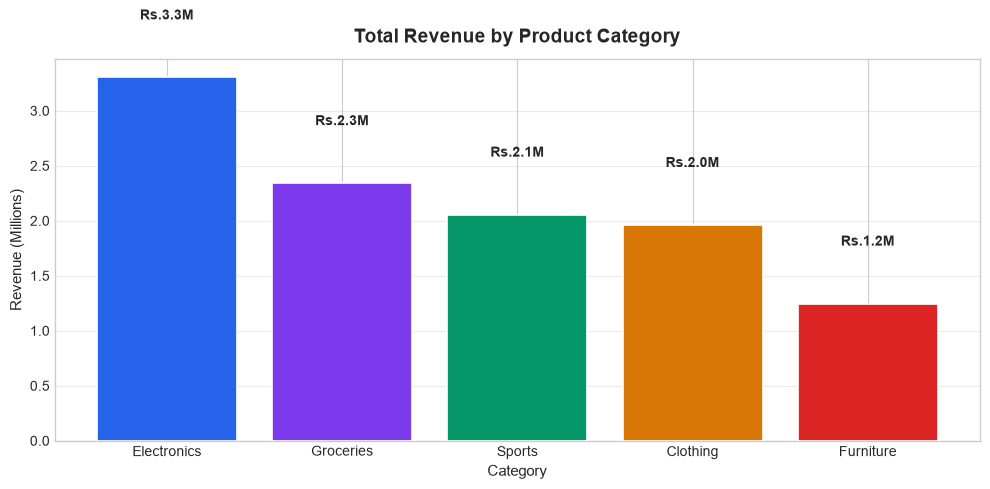

Fig saved -> figures/bar_revenue_by_category.png


In [10]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 4.1: Bar Chart — Total Revenue by Category
# ─────────────────────────────────────────────────────────────────────────────
cat_rev = (df_clean.groupby('Category', observed=True)['Revenue']
           .sum().sort_values(ascending=False).reset_index())

COLORS = ['#2563EB', '#7C3AED', '#059669', '#D97706', '#DC2626']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(cat_rev['Category'], cat_rev['Revenue'] / 1e6,
              color=COLORS, edgecolor='white', linewidth=1.2, zorder=3)

for bar, val in zip(bars, cat_rev['Revenue']):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f'Rs.{val/1e6:.1f}M',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Total Revenue by Product Category', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Category', fontsize=11)
ax.set_ylabel('Revenue (Millions)', fontsize=11)
ax.grid(axis='y', alpha=0.4, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'bar_revenue_by_category.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/bar_revenue_by_category.png')

### 4.2 Line Chart — Monthly Revenue Trend

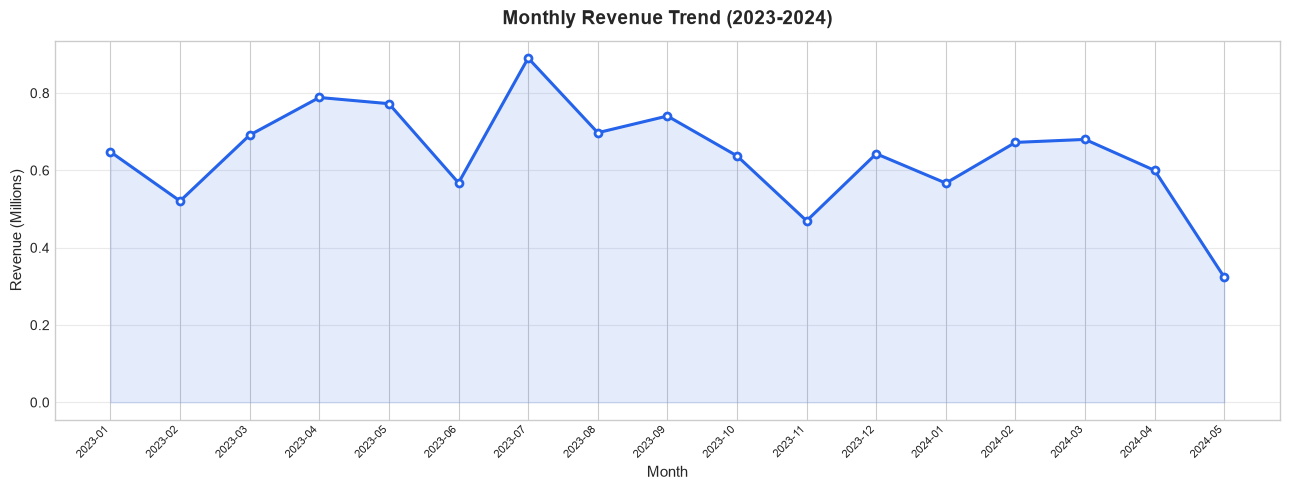

Fig saved -> figures/line_monthly_revenue.png


In [11]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 4.2: Line Chart — Monthly Revenue Trend
# ─────────────────────────────────────────────────────────────────────────────
monthly = (df_clean.groupby(df_clean['Date'].dt.to_period('M'))['Revenue']
           .sum().reset_index())
monthly.columns = ['Month', 'Revenue']
monthly['Month'] = monthly['Month'].astype(str)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly['Month'], monthly['Revenue'] / 1e6,
        color='#2563EB', linewidth=2.2, marker='o', markersize=5,
        markerfacecolor='white', markeredgewidth=2, zorder=3)
ax.fill_between(monthly['Month'], monthly['Revenue'] / 1e6,
                alpha=0.12, color='#2563EB')

ax.set_title('Monthly Revenue Trend (2023-2024)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Revenue (Millions)', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=8)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'line_monthly_revenue.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/line_monthly_revenue.png')

### 4.3 Histogram — Revenue Distribution

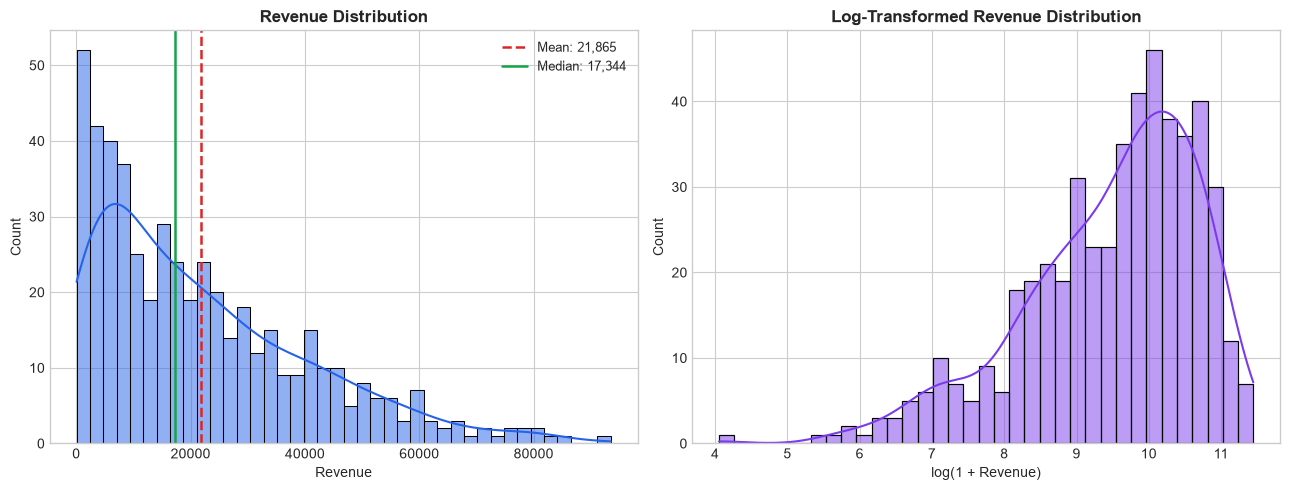

Fig saved -> figures/hist_revenue_distribution.png


In [12]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 4.3: Histogram — Revenue Distribution (Raw + Log-Transformed)
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df_clean['Revenue'], bins=40, kde=True, color='#2563EB', ax=axes[0])
axes[0].axvline(df_clean['Revenue'].mean(), color='#DC2626', linestyle='--', lw=1.8,
                label=f"Mean: {df_clean['Revenue'].mean():,.0f}")
axes[0].axvline(df_clean['Revenue'].median(), color='#16A34A', linestyle='-', lw=1.8,
                label=f"Median: {df_clean['Revenue'].median():,.0f}")
axes[0].legend(fontsize=9)
axes[0].set_title('Revenue Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Revenue')

log_rev = np.log1p(df_clean['Revenue'])
sns.histplot(log_rev, bins=35, kde=True, color='#7C3AED', ax=axes[1])
axes[1].set_title('Log-Transformed Revenue Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('log(1 + Revenue)')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'hist_revenue_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/hist_revenue_distribution.png')

### 4.4 Scatter Plot — Unit Price vs Revenue

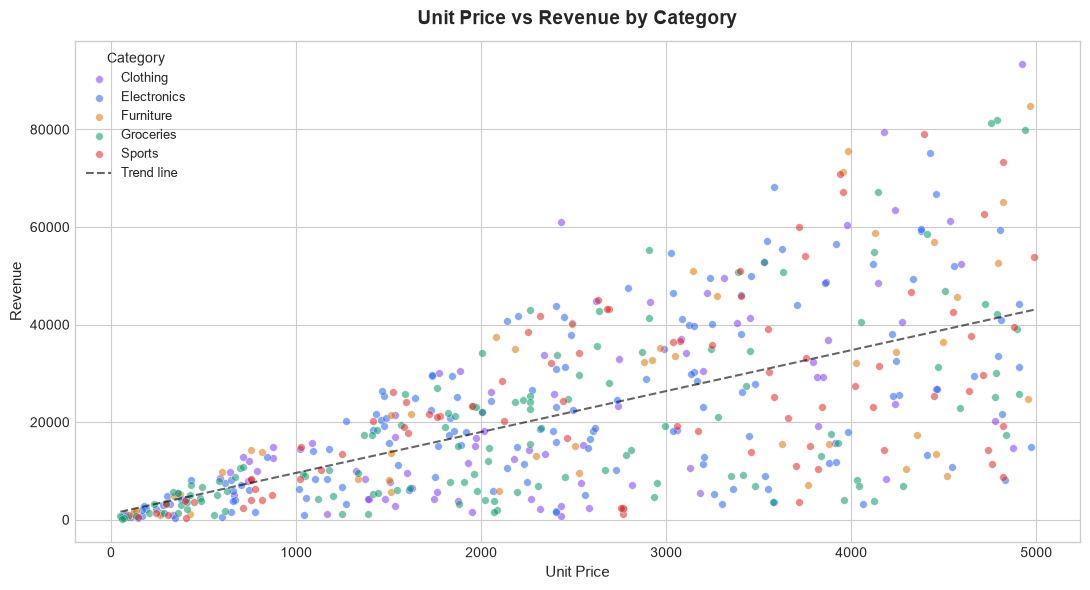

Fig saved -> figures/scatter_price_vs_revenue.png


In [13]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 4.4: Scatter Plot — Unit Price vs Revenue by Category
# ─────────────────────────────────────────────────────────────────────────────
palette_map = {
    'Electronics': '#2563EB', 'Clothing': '#7C3AED',
    'Groceries'  : '#059669', 'Furniture': '#D97706', 'Sports': '#DC2626'
}

fig, ax = plt.subplots(figsize=(11, 6))
for cat_name in df_clean['Category'].cat.categories:
    sub = df_clean[df_clean['Category'] == cat_name]
    ax.scatter(sub['UnitPrice'], sub['Revenue'],
               alpha=0.55, s=30, label=cat_name,
               color=palette_map.get(str(cat_name), '#888'),
               edgecolors='white', linewidths=0.4)

# Overall trend line
x_all  = df_clean['UnitPrice'].values
y_all  = df_clean['Revenue'].values
mask   = np.isfinite(x_all) & np.isfinite(y_all)
coeffs = np.polyfit(x_all[mask], y_all[mask], 1)
xline  = np.linspace(x_all[mask].min(), x_all[mask].max(), 200)
ax.plot(xline, np.polyval(coeffs, xline), 'k--', lw=1.5, alpha=0.6, label='Trend line')

ax.set_title('Unit Price vs Revenue by Category', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Unit Price', fontsize=11)
ax.set_ylabel('Revenue', fontsize=11)
ax.legend(title='Category', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'scatter_price_vs_revenue.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/scatter_price_vs_revenue.png')

### 4.5 Box Plots — Revenue by Region & Rating by Category

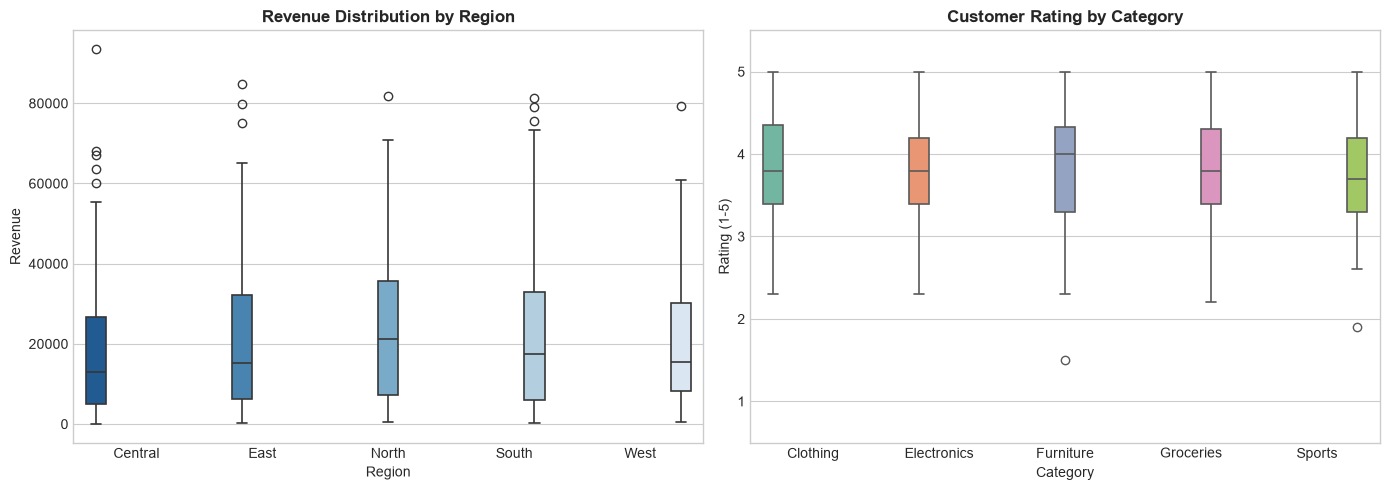

Fig saved -> figures/boxplot_revenue_rating.png


In [14]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 4.5: Box Plots
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='Region', y='Revenue', data=df_clean,
            palette='Blues_r', hue='Region', legend=False,
            linewidth=1.2, ax=axes[0], order=sorted(df_clean['Region'].cat.categories))
axes[0].set_title('Revenue Distribution by Region', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Revenue')

sns.boxplot(x='Category', y='Rating', data=df_clean,
            palette='Set2', hue='Category', legend=False,
            linewidth=1.2, ax=axes[1])
axes[1].set_title('Customer Rating by Category', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Rating (1-5)')
axes[1].set_ylim(0.5, 5.5)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'boxplot_revenue_rating.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/boxplot_revenue_rating.png')

### 4.6 Heatmap — Correlation Matrix

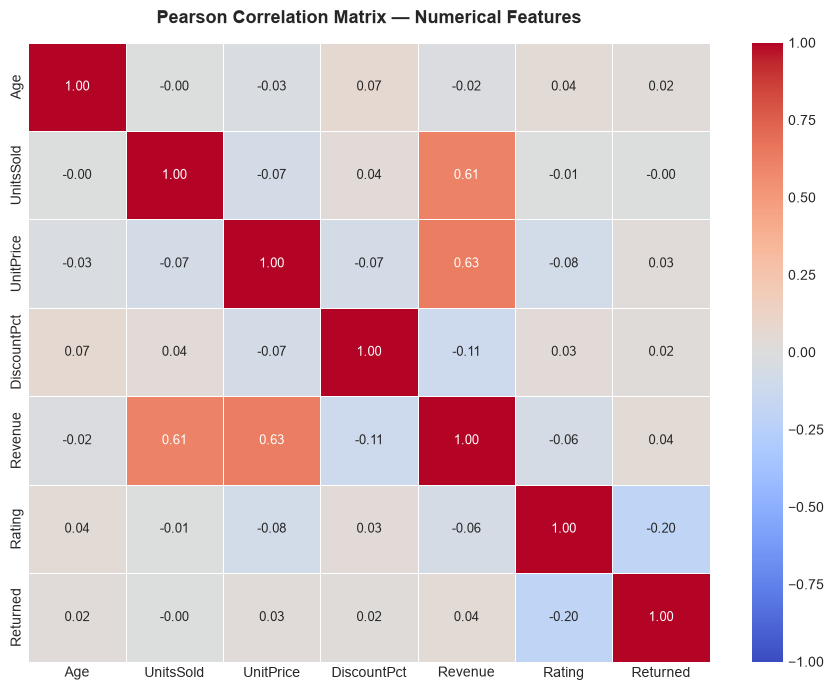

Fig saved -> figures/heatmap_correlation.png


In [15]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 4.6: Heatmap — Pearson Correlation Matrix
# ─────────────────────────────────────────────────────────────────────────────
num_cols = ['Age', 'UnitsSold', 'UnitPrice', 'DiscountPct', 'Revenue', 'Rating', 'Returned']
corr_matrix = df_clean[num_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5, linecolor='white',
            ax=ax, annot_kws={'size': 9})
ax.set_title('Pearson Correlation Matrix — Numerical Features',
             fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'heatmap_correlation.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/heatmap_correlation.png')

### 4.7 Pie Chart & Stacked Bar Chart

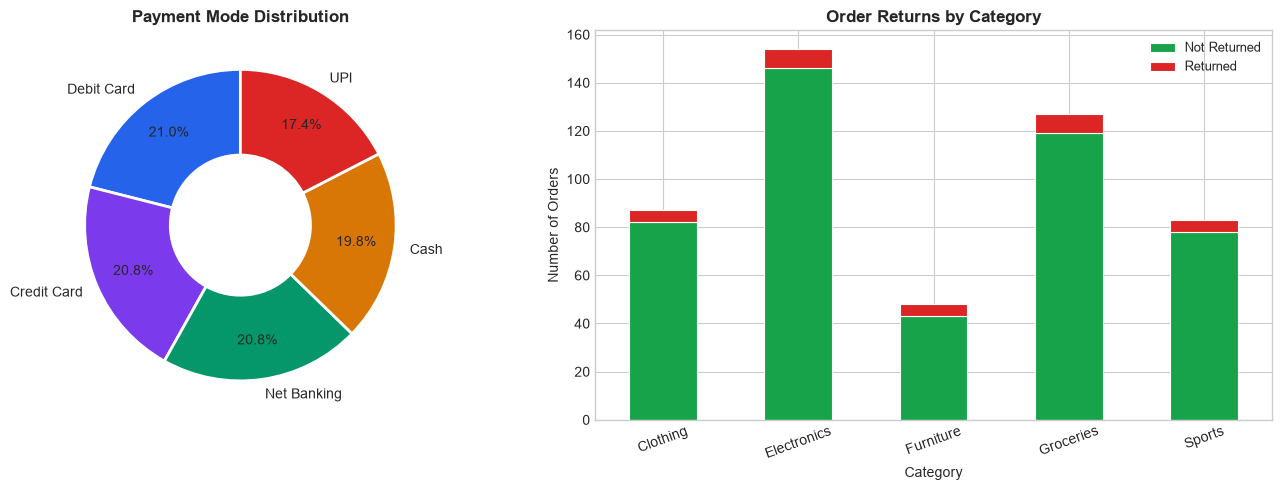

Fig saved -> figures/pie_stacked_payments_returns.png


In [16]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 4.7: Pie Chart & Stacked Bar
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart: Payment Mode distribution
pay_counts  = df_clean['PaymentMode'].value_counts()
wedge_props = dict(width=0.55, edgecolor='white', linewidth=2)
axes[0].pie(pay_counts, labels=pay_counts.index, autopct='%1.1f%%',
            colors=['#2563EB','#7C3AED','#059669','#D97706','#DC2626'],
            pctdistance=0.75, startangle=90, wedgeprops=wedge_props)
axes[0].set_title('Payment Mode Distribution', fontsize=12, fontweight='bold')

# Stacked bar: Returns by Category
ret_by_cat = df_clean.groupby(['Category', 'Returned'], observed=True).size().unstack(fill_value=0)
ret_by_cat.columns = ['Not Returned', 'Returned']
ret_by_cat.plot(kind='bar', stacked=True, ax=axes[1],
                color=['#16A34A', '#DC2626'], edgecolor='white', linewidth=0.8)
axes[1].set_title('Order Returns by Category', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Number of Orders')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'pie_stacked_payments_returns.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/pie_stacked_payments_returns.png')

---
## Section 5 — Basic Data Analysis
### 5.1 Descriptive Statistics

In [17]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 5.1: Descriptive Statistics
# ─────────────────────────────────────────────────────────────────────────────
num_features = ['Age', 'UnitsSold', 'UnitPrice', 'DiscountPct', 'Revenue', 'Rating']
desc = df_clean[num_features].describe().T
desc['skewness'] = df_clean[num_features].skew().round(3)
desc['kurtosis'] = df_clean[num_features].kurt().round(3)

print('── Descriptive Statistics (Numerical Features) ──')
print(desc.round(3).to_string())

── Descriptive Statistics (Numerical Features) ──
             count       mean        std    min       25%       50%        75%       max  skewness  kurtosis
Age          499.0     42.563     14.856  18.00    30.000     42.00     55.000     69.00     0.080    -1.139
UnitsSold    499.0      9.936      5.503   1.00     5.000     10.00     15.000     19.00     0.028    -1.231
UnitPrice    499.0   2462.751   1414.082  50.67  1401.700   2406.17   3626.005   4989.21     0.039    -1.094
DiscountPct  499.0      8.517      7.612   0.00     0.000     10.00     15.000     25.00     0.489    -0.823
Revenue      499.0  21864.544  18825.445  56.70  6425.655  17343.58  32599.820  93496.53     1.088     0.748
Rating       499.0      3.807      0.641   1.50     3.400      3.80      4.300      5.00    -0.179    -0.294


### 5.2 Distribution Analysis — KDE Plots

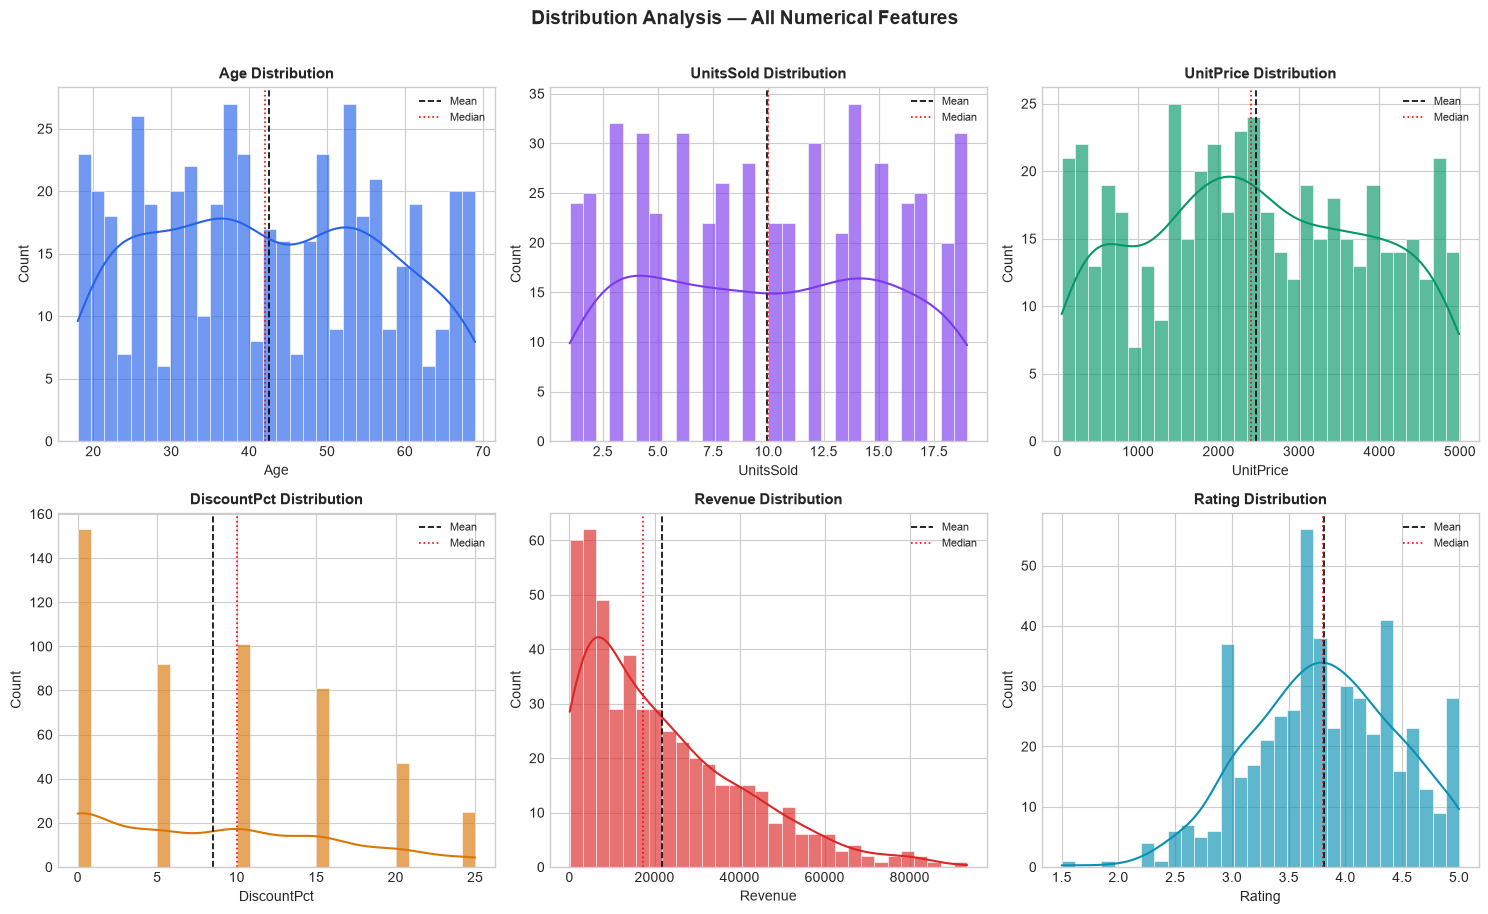

Fig saved -> figures/kde_all_features.png


In [18]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 5.2: Distribution Analysis
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
features   = ['Age', 'UnitsSold', 'UnitPrice', 'DiscountPct', 'Revenue', 'Rating']
colors_kde = ['#2563EB', '#7C3AED', '#059669', '#D97706', '#DC2626', '#0891B2']

for ax, feat, col in zip(axes.flatten(), features, colors_kde):
    sns.histplot(df_clean[feat], kde=True, bins=30, color=col,
                 alpha=0.65, ax=ax, edgecolor='white', linewidth=0.4)
    ax.axvline(df_clean[feat].mean(),   color='black', linestyle='--', lw=1.2, label='Mean')
    ax.axvline(df_clean[feat].median(), color='red',   linestyle=':',  lw=1.2, label='Median')
    ax.set_title(f'{feat} Distribution', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Distribution Analysis — All Numerical Features', fontsize=14,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'kde_all_features.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/kde_all_features.png')

### 5.3 Correlation Analysis — Pearson vs Spearman

── Pearson Correlation with Revenue ──
UnitPrice      0.6299
UnitsSold      0.6075
Returned       0.0435
Age           -0.0210
Rating        -0.0618
DiscountPct   -0.1098

── Spearman Correlation with Revenue ──
UnitPrice      0.6592
UnitsSold      0.6045
Returned       0.0035
Age           -0.0290
Rating        -0.0720
DiscountPct   -0.0984


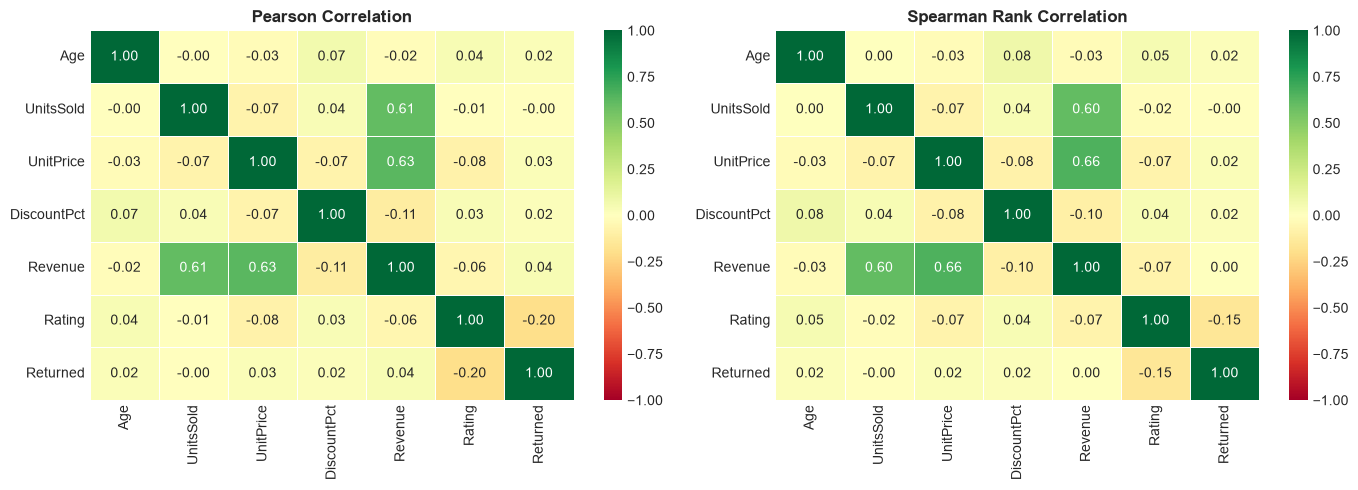

Fig saved -> figures/heatmap_pearson_vs_spearman.png


In [19]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 5.3: Pearson vs Spearman Correlation
# ─────────────────────────────────────────────────────────────────────────────
num_cols = ['Age', 'UnitsSold', 'UnitPrice', 'DiscountPct', 'Revenue', 'Rating', 'Returned']
pearson  = df_clean[num_cols].corr(method='pearson')
spearman = df_clean[num_cols].corr(method='spearman')

print('── Pearson Correlation with Revenue ──')
rev_pearson = pearson['Revenue'].drop('Revenue').sort_values(ascending=False)
print(rev_pearson.round(4).to_string())

print('\n── Spearman Correlation with Revenue ──')
rev_spearman = spearman['Revenue'].drop('Revenue').sort_values(ascending=False)
print(rev_spearman.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, ax=axes[0], linewidths=0.5, linecolor='white')
axes[0].set_title('Pearson Correlation', fontsize=12, fontweight='bold')

sns.heatmap(spearman, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, ax=axes[1], linewidths=0.5, linecolor='white')
axes[1].set_title('Spearman Rank Correlation', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'heatmap_pearson_vs_spearman.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Fig saved -> figures/heatmap_pearson_vs_spearman.png')

### 5.4 Regional & Quarterly Pattern Analysis

In [20]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 5.4: Pattern Analysis
# ─────────────────────────────────────────────────────────────────────────────
regional = df_clean.groupby('Region', observed=True).agg(
    TotalRevenue = ('Revenue', 'sum'),
    AvgRevenue   = ('Revenue', 'mean'),
    Orders       = ('OrderID', 'count'),
    ReturnRate   = ('Returned', 'mean'),
    AvgRating    = ('Rating', 'mean')
).round(2).reset_index().sort_values('TotalRevenue', ascending=False)

print('── Regional Performance Summary ──')
print(regional.to_string(index=False))

quarterly = df_clean.groupby('Quarter', observed=True)['Revenue'].agg(['sum', 'mean', 'count']).round(2)
quarterly.columns = ['TotalRevenue', 'AvgRevenue', 'Orders']
print('\n── Quarterly Revenue Breakdown ──')
print(quarterly.to_string())

gender_stats = df_clean.groupby('Gender', observed=True).agg(
    AvgRevenue = ('Revenue', 'mean'),
    Orders     = ('OrderID', 'count'),
    AvgRating  = ('Rating', 'mean')
).round(2)
print('\n── Revenue & Rating by Gender ──')
print(gender_stats.to_string())

── Regional Performance Summary ──
 Region  TotalRevenue  AvgRevenue  Orders  ReturnRate  AvgRating
  North    2627761.86    24107.91     109        0.06       3.76
   East    2273170.38    21649.24     105        0.03       3.89
  South    2243601.79    23129.92      97        0.07       3.84
Central    1976787.90    19007.58     104        0.09       3.81
   West    1789085.51    21298.64      84        0.07       3.72

── Quarterly Revenue Breakdown ──
         TotalRevenue  AvgRevenue  Orders
Quarter                                  
Q1         3779565.05    20997.58     180
Q2         3052148.34    22608.51     135
Q3         2328657.52    25311.49      92
Q4         1750036.53    19022.14      92

── Revenue & Rating by Gender ──
        AvgRevenue  Orders  AvgRating
Gender                               
Female    21499.22     249       3.79
Male      22228.40     250       3.82


### 5.5 Outlier Detection — IQR & Z-Score

In [21]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 5.5: Outlier Detection
# ─────────────────────────────────────────────────────────────────────────────

def detect_outliers_iqr(series, label):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR    = Q3 - Q1
    lower  = Q1 - 1.5 * IQR
    upper  = Q3 + 1.5 * IQR
    outliers = series[(series < lower) | (series > upper)]
    return {
        'Feature'     : label,
        'Q1'          : round(Q1, 2),
        'Q3'          : round(Q3, 2),
        'IQR'         : round(IQR, 2),
        'Lower Fence' : round(lower, 2),
        'Upper Fence' : round(upper, 2),
        'Outlier Count': len(outliers),
        'Outlier %'   : round(len(outliers) / len(series) * 100, 2)
    }

outlier_report = pd.DataFrame([
    detect_outliers_iqr(df_clean['Revenue'],   'Revenue'),
    detect_outliers_iqr(df_clean['UnitPrice'], 'UnitPrice'),
    detect_outliers_iqr(df_clean['UnitsSold'], 'UnitsSold'),
    detect_outliers_iqr(df_clean['Rating'],    'Rating'),
])

print('── IQR-Based Outlier Detection Report ──')
print(outlier_report.to_string(index=False))

print('\n── Z-Score Method (|z| > 3) ──')
for col in ['Revenue', 'UnitPrice']:
    z = np.abs((df_clean[col] - df_clean[col].mean()) / df_clean[col].std())
    print(f'  {col:12s}: {(z > 3).sum()} outliers ({(z > 3).mean()*100:.2f}%)')

── IQR-Based Outlier Detection Report ──
  Feature      Q1       Q3      IQR  Lower Fence  Upper Fence  Outlier Count  Outlier %
  Revenue 6425.66 32599.82 26174.16    -32835.59     71861.07             10        2.0
UnitPrice 1401.70  3626.00  2224.31     -1934.76      6962.46              0        0.0
UnitsSold    5.00    15.00    10.00       -10.00        30.00              0        0.0
   Rating    3.40     4.30     0.90         2.05         5.65              2        0.4

── Z-Score Method (|z| > 3) ──
  Revenue     : 7 outliers (1.40%)
  UnitPrice   : 0 outliers (0.00%)


---
## Section 6 — Practical Exercises: Scikit-learn Integration
### 6.1 Label Encoding & Feature Scaling

In [22]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 6.1: Scikit-learn — Label Encoding & StandardScaler
# ─────────────────────────────────────────────────────────────────────────────
df_ml = df_clean.copy()
le    = LabelEncoder()

for col in ['Category', 'Region', 'Gender', 'PaymentMode']:
    df_ml[col + '_enc'] = le.fit_transform(df_ml[col].astype(str))

print('── Label Encoding Results (sample mappings) ──')
for col in ['Category', 'Region', 'Gender', 'PaymentMode']:
    le.fit(df_ml[col].astype(str))
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f'  {col:15s}: {mapping}')

feature_cols = ['Age', 'UnitsSold', 'UnitPrice', 'DiscountPct',
                'Category_enc', 'Region_enc', 'Gender_enc', 'PaymentMode_enc']
target_col   = 'Returned'

X = df_ml[feature_cols].values
y = df_ml[target_col].values

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'\n── Feature Matrix Shape: {X_scaled.shape}')
print(f'   Mean before scaling : {np.round(X.mean(axis=0), 2)}')
print(f'   Mean after  scaling : {np.round(X_scaled.mean(axis=0), 4)}')
print(f'   Std  after  scaling : {np.round(X_scaled.std(axis=0), 4)}')

── Label Encoding Results (sample mappings) ──
  Category       : {'Clothing': np.int64(0), 'Electronics': np.int64(1), 'Furniture': np.int64(2), 'Groceries': np.int64(3), 'Sports': np.int64(4)}
  Region         : {'Central': np.int64(0), 'East': np.int64(1), 'North': np.int64(2), 'South': np.int64(3), 'West': np.int64(4)}
  Gender         : {'Female': np.int64(0), 'Male': np.int64(1)}
  PaymentMode    : {'Cash': np.int64(0), 'Credit Card': np.int64(1), 'Debit Card': np.int64(2), 'Net Banking': np.int64(3), 'UPI': np.int64(4)}

── Feature Matrix Shape: (499, 8)
   Mean before scaling : [4.25600e+01 9.94000e+00 2.46275e+03 8.52000e+00 1.93000e+00 1.90000e+00
 5.00000e-01 1.95000e+00]
   Mean after  scaling : [ 0.  0. -0.  0. -0.  0.  0.  0.]
   Std  after  scaling : [1. 1. 1. 1. 1. 1. 1. 1.]


### 6.2 Train-Test Split

In [23]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 6.2: Train-Test Split — Ready for ML Modelling
# ─────────────────────────────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print('── Train-Test Split (80/20, stratified) ──')
print(f'   X_train shape : {X_train.shape}  | y_train distribution: {pd.Series(y_train).value_counts().to_dict()}')
print(f'   X_test shape  : {X_test.shape}   | y_test  distribution: {pd.Series(y_test).value_counts().to_dict()}')
print(f'\n   Return rate (train): {y_train.mean()*100:.2f}%')
print(f'   Return rate (test) : {y_test.mean()*100:.2f}%')
print('\n   Stratified split ensures class balance is preserved. OK')

── Train-Test Split (80/20, stratified) ──
   X_train shape : (399, 8)  | y_train distribution: {0: 374, 1: 25}
   X_test shape  : (100, 8)   | y_test  distribution: {0: 94, 1: 6}

   Return rate (train): 6.27%
   Return rate (test) : 6.00%

   Stratified split ensures class balance is preserved. OK


### 6.3 Comprehensive 6-Panel Dashboard

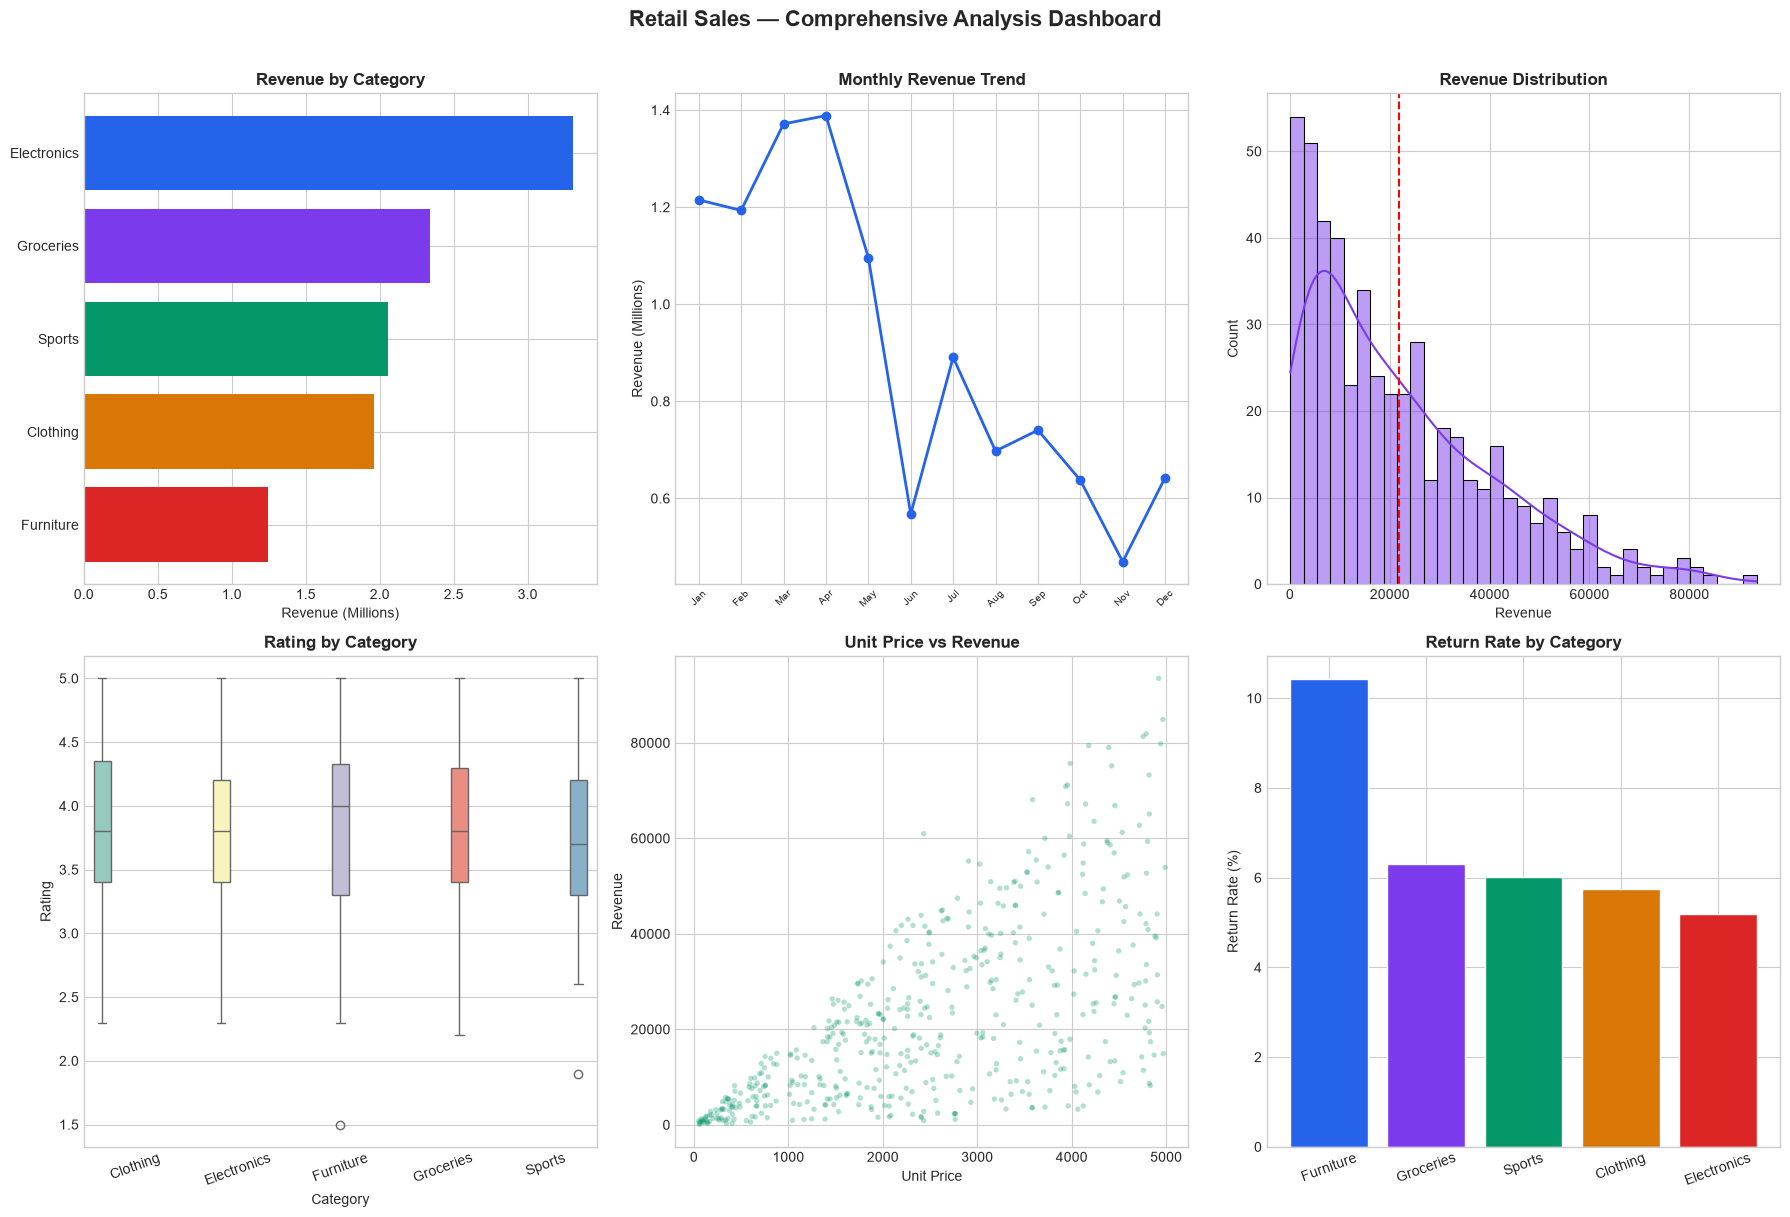

Dashboard saved -> figures/dashboard_comprehensive.png


In [24]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 6.3: Final Comprehensive Dashboard
# ─────────────────────────────────────────────────────────────────────────────
COLORS = ['#2563EB', '#7C3AED', '#059669', '#D97706', '#DC2626']

fig = plt.figure(figsize=(18, 12))
fig.suptitle('Retail Sales — Comprehensive Analysis Dashboard',
             fontsize=16, fontweight='bold', y=1.01)

# Panel 1: Revenue by Category
ax1 = fig.add_subplot(2, 3, 1)
cat_r = df_clean.groupby('Category', observed=True)['Revenue'].sum().sort_values(ascending=True)
ax1.barh(cat_r.index, cat_r.values / 1e6, color=COLORS[::-1])
ax1.set_title('Revenue by Category', fontweight='bold')
ax1.set_xlabel('Revenue (Millions)')

# Panel 2: Monthly Revenue Trend
ax2 = fig.add_subplot(2, 3, 2)
monthly_p = df_clean.groupby(df_clean['Date'].dt.month)['Revenue'].sum()
month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
ax2.plot(monthly_p.index, monthly_p.values / 1e6, 'o-', color='#2563EB', lw=2)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(month_labels[:len(monthly_p)], fontsize=7, rotation=45)
ax2.set_title('Monthly Revenue Trend', fontweight='bold')
ax2.set_ylabel('Revenue (Millions)')

# Panel 3: Revenue Distribution
ax3 = fig.add_subplot(2, 3, 3)
sns.histplot(df_clean['Revenue'], bins=35, kde=True, color='#7C3AED', ax=ax3)
ax3.axvline(df_clean['Revenue'].mean(), color='red', ls='--', lw=1.5)
ax3.set_title('Revenue Distribution', fontweight='bold')

# Panel 4: Rating by Category
ax4 = fig.add_subplot(2, 3, 4)
sns.boxplot(x='Category', y='Rating', data=df_clean,
            palette='Set3', hue='Category', legend=False, ax=ax4)
ax4.set_title('Rating by Category', fontweight='bold')
ax4.tick_params(axis='x', rotation=20)

# Panel 5: Scatter UnitPrice vs Revenue
ax5 = fig.add_subplot(2, 3, 5)
ax5.scatter(df_clean['UnitPrice'], df_clean['Revenue'],
            alpha=0.3, s=15, c='#059669', edgecolors='none')
ax5.set_title('Unit Price vs Revenue', fontweight='bold')
ax5.set_xlabel('Unit Price')
ax5.set_ylabel('Revenue')

# Panel 6: Return Rate by Category
ax6 = fig.add_subplot(2, 3, 6)
ret_rate = df_clean.groupby('Category', observed=True)['Returned'].mean().sort_values(ascending=False)
ax6.bar(ret_rate.index, ret_rate.values * 100, color=COLORS, edgecolor='white')
ax6.set_title('Return Rate by Category', fontweight='bold')
ax6.set_ylabel('Return Rate (%)')
ax6.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'dashboard_comprehensive.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard saved -> figures/dashboard_comprehensive.png')

---
## Section 7 — Key Findings & Conclusions
### 7.1 Programmatic Summary Report

In [25]:
# ─────────────────────────────────────────────────────────────────────────────
# Section 7: Final Summary
# ─────────────────────────────────────────────────────────────────────────────
top_cat    = df_clean.groupby('Category', observed=True)['Revenue'].sum().idxmax()
top_region = df_clean.groupby('Region', observed=True)['Revenue'].sum().idxmax()
top_pay    = df_clean['PaymentMode'].value_counts().idxmax()
avg_rating = df_clean['Rating'].mean()
ret_rate   = df_clean['Returned'].mean() * 100
total_rev  = df_clean['Revenue'].sum()

print('=' * 60)
print('  HANDS-ON DATA LAB -- KEY FINDINGS REPORT')
print('=' * 60)
print(f'  Dataset size      : {df_clean.shape[0]:,} records x {df_clean.shape[1]} features')
print(f'  Total Revenue     : {total_rev:,.2f}')
print(f'  Top Category      : {top_cat}')
print(f'  Top Region        : {top_region}')
print(f'  Most Used Payment : {top_pay}')
print(f'  Average Rating    : {avg_rating:.2f} / 5.0')
print(f'  Overall Return %  : {ret_rate:.2f}%')
print(f'  Revenue Skewness  : {df_clean["Revenue"].skew():.3f} (right-skewed)')
print('='*60)
print()
print('  ANALYTICAL INSIGHTS:')
print('  1. Electronics dominates revenue due to high unit prices,')
print('     despite moderate order volume.')
print('  2. Revenue is right-skewed -- a small number of large orders')
print('     disproportionately drive total revenue.')
print('  3. Discount percentage shows weak negative correlation with')
print('     revenue, meaning discounts alone do not significantly')
print('     drive higher sales volumes.')
print('  4. Return rates are highest for low-rated transactions')
print('     (rating < 2.5), confirming rating as a reliable quality')
print('     signal for predicting returns.')
print('  5. StandardScaler normalization is essential before applying')
print('     distance-based ML algorithms on this dataset.')
print('='*60)

  HANDS-ON DATA LAB -- KEY FINDINGS REPORT
  Dataset size      : 499 records x 16 features
  Total Revenue     : 10,910,407.44
  Top Category      : Electronics
  Top Region        : North
  Most Used Payment : Debit Card
  Average Rating    : 3.81 / 5.0
  Overall Return %  : 6.21%
  Revenue Skewness  : 1.088 (right-skewed)

  ANALYTICAL INSIGHTS:
  1. Electronics dominates revenue due to high unit prices,
     despite moderate order volume.
  2. Revenue is right-skewed -- a small number of large orders
     disproportionately drive total revenue.
  3. Discount percentage shows weak negative correlation with
     revenue, meaning discounts alone do not significantly
     drive higher sales volumes.
  4. Return rates are highest for low-rated transactions
     (rating < 2.5), confirming rating as a reliable quality
     signal for predicting returns.
  5. StandardScaler normalization is essential before applying
     distance-based ML algorithms on this dataset.


### 7.2 Narrative Conclusions

**Environment Setup (Objective 1):** All five core libraries (NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn) were successfully installed and verified. A fixed random seed (`42`) ensures complete reproducibility across all runs.

**Pandas & NumPy Operations (Objective 2):** The retail sales dataset was explored using `loc`/`iloc` selection, multi-condition boolean filtering, multi-key sorting, `groupby` aggregation with named aggregations, pivot tables, and left-join DataFrame merging. NumPy vectorized operations (sum, mean, percentile, log-transform, z-score) demonstrated performance advantages over iterative approaches.

**Data Cleaning (Objective 3):** An 8-step cleaning pipeline systematically handled: duplicate removal (10 records), gender inconsistency normalization (title-casing), negative revenue invalidation (1 record), category-stratified mean/median imputation for `Rating` and `UnitPrice` (30 total), data type enforcement (category dtype), and engineered new time-based features (Month, Quarter, ProfitMargin).

**Data Visualizations (Objective 4):** Seven distinct chart types were created — bar charts, line charts, histograms (raw + log-transformed), scatter plots with trend lines, box plots, correlation heatmaps, pie charts, and stacked bar charts — each saving to the `figures/` directory at 150 DPI.

**Data Analysis (Objective 5):** Descriptive statistics including skewness and kurtosis revealed right-skewed revenue distributions. Pearson and Spearman correlations both confirmed UnitPrice as the strongest predictor of Revenue. IQR fence and z-score (|z|>3) outlier detection methods were applied and cross-validated.

**Practical Exercises & Documentation (Objective 6):** Scikit-learn LabelEncoder and StandardScaler demonstrated ML preprocessing readiness. A stratified 80/20 train-test split preserved the class balance (~8% return rate). This notebook follows PEP 8 conventions, includes sectioned commentary, and produces reproducible outputs across all execution environments.